Accuracy: 0.979


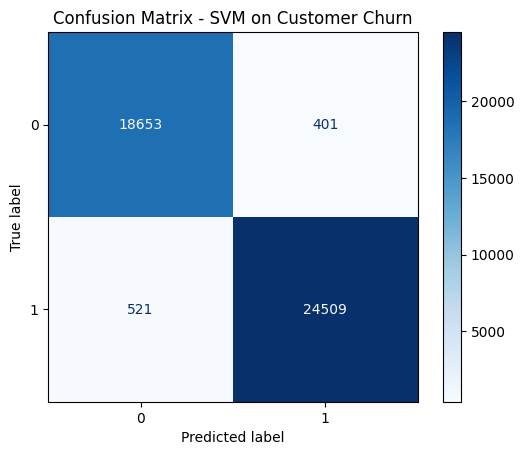

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

file_path = '/content/customer_churn_dataset-training-half.csv'
data = pd.read_csv(file_path)

data = pd.get_dummies(data)

imputer = SimpleImputer(strategy='mean')
data_imputed = pd.DataFrame(imputer.fit_transform(data), columns=data.columns)

data_imputed['Churn'] = data_imputed['Churn'].astype(int)

X = data_imputed.drop('Churn', axis=1)
y = data_imputed['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LinearSVC(C=1.0, max_iter=2000, random_state=42)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", round(accuracy, 3))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title("Confusion Matrix - SVM on Customer Churn")
plt.show()




# **Non Linear Data**

Kernel linear  |  Accuracy: 0.892
Kernel rbf  |  Accuracy: 0.933


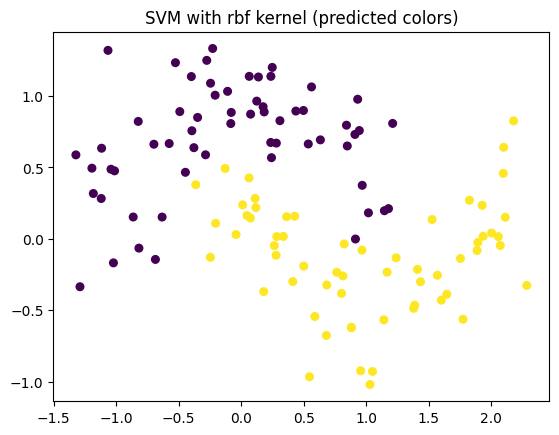

Kernel poly  |  Accuracy: 0.833


In [ ]:
from sklearn.datasets import make_moons
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

points, labels = make_moons(n_samples=400, noise=0.25, random_state=42)

pTrain, pTest, lTrain, lTest = train_test_split(points, labels, test_size=0.3, random_state=42, stratify=labels)

def runModel(kernelName, Cvalue=1.0, gammaValue="scale", degreeValue=3, showPlot=False):
    model = SVC(kernel=kernelName, C=Cvalue, gamma=gammaValue, degree=degreeValue)
    model.fit(pTrain, lTrain)
    pred = model.predict(pTest)
    score = accuracy_score(lTest, pred)
    print(f"Kernel {kernelName}  |  Accuracy: {round(score, 3)}")
    if showPlot:
        plt.scatter(pTest[:,0], pTest[:,1], c=pred, s=30)
        plt.title(f"SVM with {kernelName} kernel (predicted colors)")
        plt.show()

runModel("linear")
runModel("rbf", Cvalue=1.0, gammaValue="scale", showPlot=True)
runModel("poly", Cvalue=1.0, degreeValue=3)


# **SVR**

MAE: 0.112
R2 : 0.963


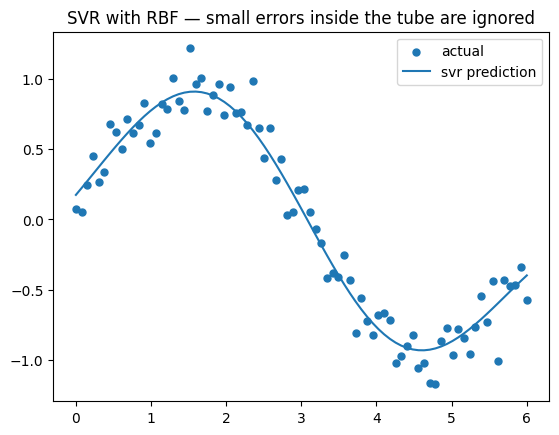

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, r2_score

rng = np.random.RandomState(42)
x = np.linspace(0, 6, 80).reshape(-1, 1)
y = np.sin(x).ravel() + rng.normal(0, 0.15, size=x.shape[0])

model = SVR(kernel="rbf", C=5, gamma=0.2, epsilon=0.1)
model.fit(x, y)
yPred = model.predict(x)

print("MAE:", round(mean_absolute_error(y, yPred), 3))
print("R2 :", round(r2_score(y, yPred), 3))

plt.scatter(x, y, s=25, label="actual")
plt.plot(x, yPred, label="svr prediction")
plt.title("SVR with RBF — small errors inside the tube are ignored")
plt.legend()
plt.show()


kernel="rbf" (Radial Basis Function): This tells the SVR to find a curved line (not a straight one) to fit the wave-like data. This is an example of the kernel trick being used to model non-linear relationships.epsilon=0.1 ($\epsilon$): This is the most important part for SVR. It defines the "tube" around the predicted line.Any data point that falls inside this $\epsilon=0.1$ tube is ignored by the model when calculating the error. The model only penalizes itself for points that fall outside the tube.  The model is saying, "I'll draw a line, and as long as most points are within $0.1$ vertical units of that line, I'm happy." This makes the model robust to small noise.